## Retail Demand Forecasting

Building a simple model that predicts total monthly sales (all products + all stores) for the next 3 months.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
# Load the cleaned datasets
sales = pd.read_parquet("../data/cleaned/sales_cleaned.parquet")
customers = pd.read_parquet("../data/cleaned/customers_cleaned.parquet")
products = pd.read_parquet("../data/cleaned/products_cleaned.parquet")
stores = pd.read_parquet("../data/cleaned/stores_cleaned.parquet")
promotions = pd.read_parquet("../data/cleaned/promotions_cleaned.parquet")
holidays = pd.read_parquet("../data/cleaned/public_holidays_cleaned.parquet")
cpi = pd.read_parquet("../data/cleaned/national_cpi_monthly_cleaned.parquet")

## Step 1 — Prepare total monthly demand

In [3]:
# Make sure dates are proper dates
sales["TransactionDate"] = pd.to_datetime(sales["TransactionDate"])

# Add up all units sold each month
monthly_demand = (
    sales
    .assign(Month=sales["TransactionDate"].dt.to_period("M").dt.to_timestamp())
    .groupby("Month")["Quantity"]
    .sum()
    .sort_index()
    .rename("TotalUnitsSold")
    .to_frame()
)

# Fill any missing months with 0
all_months = pd.date_range(
    start=monthly_demand.index.min(),
    end=monthly_demand.index.max(),
    freq="MS"
)
monthly_demand = monthly_demand.reindex(all_months, fill_value=0)
monthly_demand.index.name = "Month"

display(monthly_demand)
print("Number of months:", len(monthly_demand))
print("Total units sold:", int(monthly_demand["TotalUnitsSold"].sum()))

,TotalUnitsSold
Month,
2025-10-01,3019
2025-11-01,3128
2025-12-01,2963
2026-01-01,2920
2026-02-01,2726
2026-03-01,3140
2026-04-01,3120
2026-05-01,3081
2026-06-01,3002


Number of months: 12
Total units sold: 36151


## Step 2 — Visualize historical demand

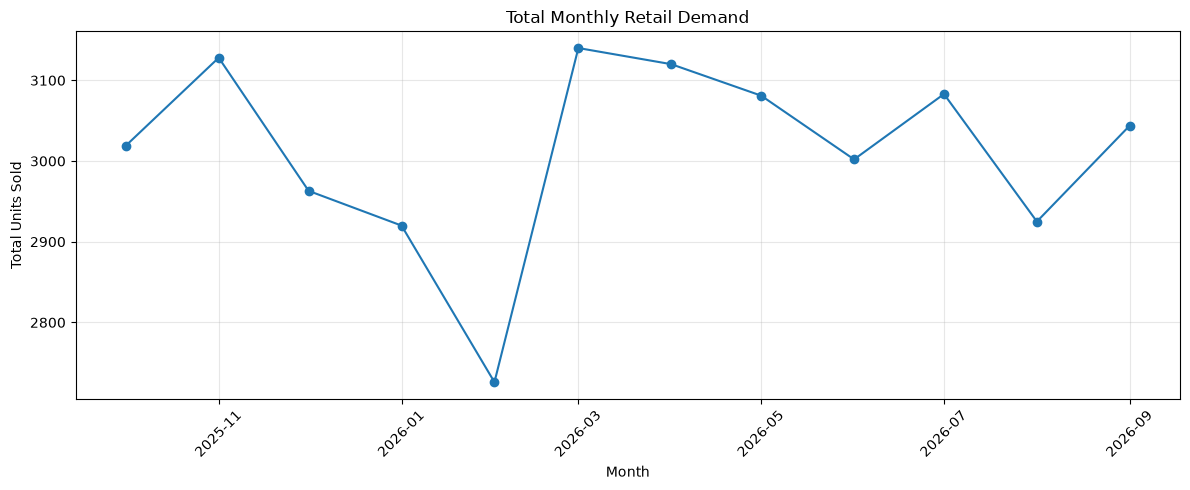

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_demand.index, monthly_demand["TotalUnitsSold"], marker="o")
plt.title("Total Monthly Retail Demand")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 3 — Create forecasting features

We use the previous three months of demand to predict the next month.

In [5]:
# Copy the data
model_data = monthly_demand.copy()

# Create lag features (previous months)
model_data["Lag1"] = model_data["TotalUnitsSold"].shift(1)  # last month
model_data["Lag2"] = model_data["TotalUnitsSold"].shift(2)  # 2 months ago
model_data["Lag3"] = model_data["TotalUnitsSold"].shift(3)  # 3 months ago

# Add month number (1 = January, 12 = December)
model_data["MonthNumber"] = model_data.index.month

# Remove the first 3 rows (they don’t have full lag data)
model_data = model_data.dropna()

display(model_data)
print("Rows ready for modelling:", len(model_data))

,TotalUnitsSold,Lag1,Lag2,Lag3,MonthNumber
Month,,,,,
2026-01-01,2920,2963.0,3128.0,3019.0,1
2026-02-01,2726,2920.0,2963.0,3128.0,2
2026-03-01,3140,2726.0,2920.0,2963.0,3
2026-04-01,3120,3140.0,2726.0,2920.0,4
2026-05-01,3081,3120.0,3140.0,2726.0,5
2026-06-01,3002,3081.0,3120.0,3140.0,6
2026-07-01,3083,3002.0,3081.0,3120.0,7
2026-08-01,2925,3083.0,3002.0,3081.0,8
2026-09-01,3044,2925.0,3083.0,3002.0,9


Rows ready for modelling: 9


## Step 4 — Split the data chronologically

Train on earlier months, test on later months. Never shuffle time-series data.

In [6]:
# Train on first 6 modelling rows → test on last 3
train_end = model_data.index[5]

features = ["Lag1", "Lag2", "Lag3", "MonthNumber"]

train = model_data.loc[model_data.index <= train_end]
test  = model_data.loc[model_data.index > train_end]

X_train = train[features]
y_train = train["TotalUnitsSold"]
X_test  = test[features]
y_test  = test["TotalUnitsSold"]

print("Training months:", len(train))
print("Testing months :", len(test))
print("Train period:", train.index.min().strftime("%Y-%m"), "→", train.index.max().strftime("%Y-%m"))
print("Test period :", test.index.min().strftime("%Y-%m"), "→", test.index.max().strftime("%Y-%m"))

Training months: 6
Testing months : 3
Train period: 2026-01 → 2026-06
Test period : 2026-07 → 2026-09


## Step 5 — Train models and make rolling predictions

We compare three approaches:
- **Naive**: simply use last month’s value
- **Linear Regression**
- **Random Forest** (kept very simple to avoid overfitting)

In [7]:
# Train the models
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=2,
    random_state=42
)
forest_model.fit(X_train, y_train)

# Rolling one-month-ahead predictions
predictions = {
    "Actual": [],
    "Naive": [],
    "Linear Regression": [],
    "Random Forest": []
}

history = monthly_demand["TotalUnitsSold"].copy()

for month in test.index:
    lag1 = history.loc[month - pd.DateOffset(months=1)]
    lag2 = history.loc[month - pd.DateOffset(months=2)]
    lag3 = history.loc[month - pd.DateOffset(months=3)]
    
    # Column names MUST match the features list exactly
    row = pd.DataFrame([{
        "Lag1": lag1,
        "Lag2": lag2,
        "Lag3": lag3,
        "MonthNumber": month.month
    }])[features]
    
    predictions["Actual"].append(history.loc[month])
    predictions["Naive"].append(lag1)
    predictions["Linear Regression"].append(linear_model.predict(row)[0])
    predictions["Random Forest"].append(forest_model.predict(row)[0])
    
    # Make the actual value known for the next prediction
    history.loc[month] = monthly_demand.loc[month, "TotalUnitsSold"]

evaluation = pd.DataFrame(predictions, index=test.index)
evaluation.index.name = "Month"

print("Predictions on test set:")
display(evaluation.round(1))

Predictions on test set:


,Actual,Naive,Linear Regression,Random Forest
Month,,,,
2026-07-01,3083,3002,3064.4,2976.6
2026-08-01,2925,3083,3129.3,2966.0
2026-09-01,3044,2925,3261.6,2958.2


## Step 6 — Evaluate forecast accuracy

In [8]:
actual = evaluation["Actual"]
metrics = []

for model_name in ["Naive", "Linear Regression", "Random Forest"]:
    predicted = evaluation[model_name]
    mae  = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = (actual - predicted).abs().sum() / actual.sum() * 100
    
    metrics.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "WAPE_Percent": round(wape, 2)
    })

model_comparison = pd.DataFrame(metrics).sort_values("MAE").reset_index(drop=True)
print("Model comparison:")
display(model_comparison)

Model comparison:


,Model,MAE,RMSE,WAPE_Percent
0,Random Forest,77.74,82.40,2.58
1,Naive,119.33,123.40,3.95
2,Linear Regression,146.81,172.64,4.87


## Step 7 — Plot actual vs predicted demand

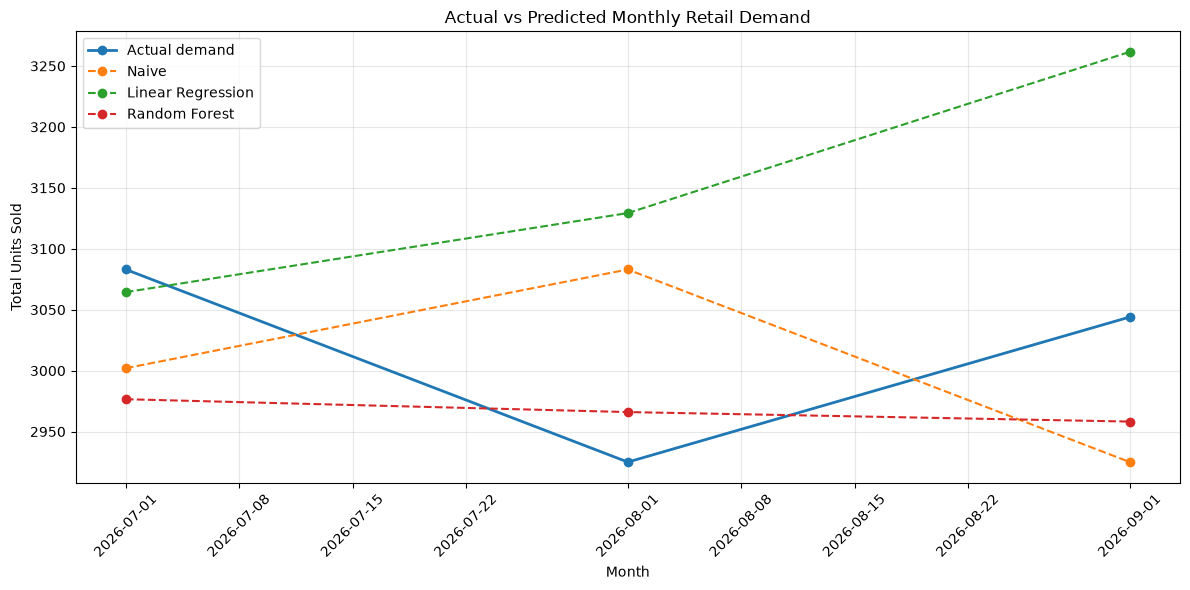

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(evaluation.index, evaluation["Actual"],
         marker="o", linewidth=2, label="Actual demand")

for model_name in ["Naive", "Linear Regression", "Random Forest"]:
    plt.plot(evaluation.index, evaluation[model_name],
             marker="o", linestyle="--", label=model_name)

plt.title("Actual vs Predicted Monthly Retail Demand")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 8 — Forecast October to December 2026

We select the model with the lowest test MAE and forecast three months ahead recursively.

In [10]:
best_model_name = model_comparison.iloc[0]["Model"]
print("Selected best model:", best_model_name)

model_lookup = {
    "Naive": None,
    "Linear Regression": linear_model,
    "Random Forest": forest_model
}
best_model = model_lookup[best_model_name]

# Start with all known historical demand
history = monthly_demand["TotalUnitsSold"].copy()

future_months = pd.date_range(
    start=monthly_demand.index.max() + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

future_predictions = []

for month in future_months:
    lag1 = history.iloc[-1]
    lag2 = history.iloc[-2]
    lag3 = history.iloc[-3]
    
    if best_model_name == "Naive":
        forecast = lag1
    else:
        row = pd.DataFrame([{
            "Lag1": lag1,
            "Lag2": lag2,
            "Lag3": lag3,
            "MonthNumber": month.month
        }])[features]
        forecast = best_model.predict(row)[0]
    
    # Demand cannot be negative
    forecast = max(0, forecast)
    
    future_predictions.append({
        "Month": month,
        "ForecastUnits": round(forecast)
    })
    
    # Use this forecast as input for the next month
    history.loc[month] = forecast

forecast_df = pd.DataFrame(future_predictions)
print("\nThree-month forecast:")
display(forecast_df)

Selected best model: Random Forest

Three-month forecast:


C:\Users\Admin\AppData\Local\Temp\ipykernel_15216\3907120880.py:47: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  history.loc[month] = forecast


,Month,ForecastUnits
0,2026-10-01,2979
1,2026-11-01,3022
2,2026-12-01,2988


## Step 9 — Plot the three-month forecast

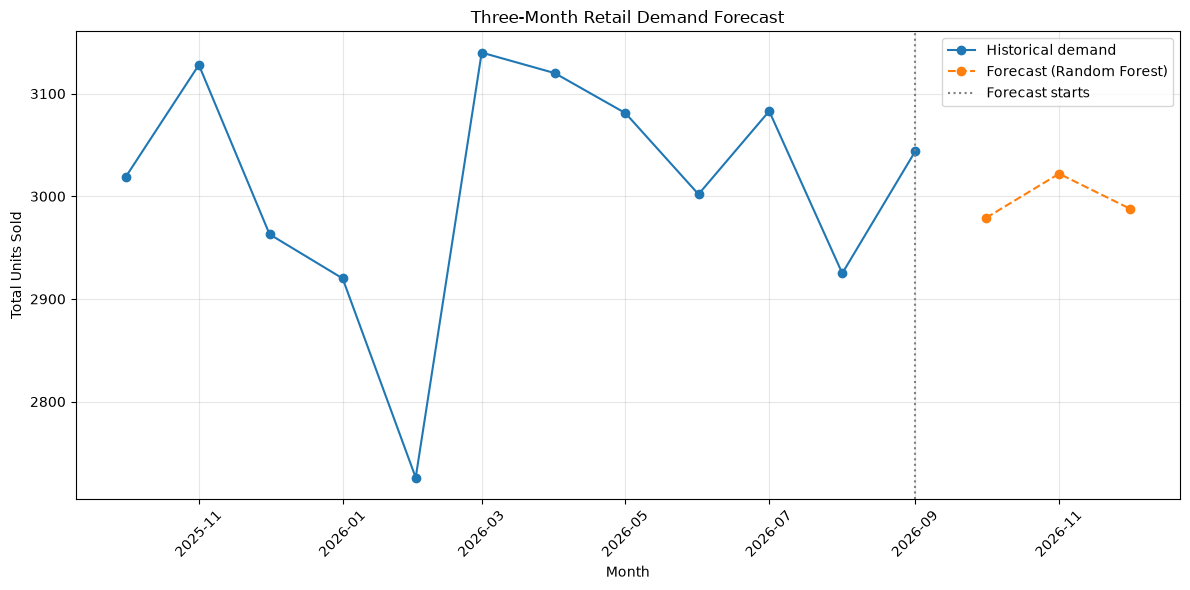

In [11]:
plt.figure(figsize=(12, 6))
plt.plot(monthly_demand.index, monthly_demand["TotalUnitsSold"],
         marker="o", label="Historical demand")
plt.plot(forecast_df["Month"], forecast_df["ForecastUnits"],
         marker="o", linestyle="--",
         label=f"Forecast ({best_model_name})")
plt.axvline(monthly_demand.index.max(),
            linestyle=":", color="gray", label="Forecast starts")

plt.title("Three-Month Retail Demand Forecast")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 10 — Conclusion

A monthly retail demand forecasting model was built using total units sold across all products and stores from October 2025 to September 2026 (12 months, 36,151 units).

**Approach**
- Features: previous 3 months of demand (lags) + month number
- Chronological split: train on Jan–Jun 2026, test on Jul–Sep 2026
- Models compared: Naïve baseline, Linear Regression, Random Forest

**Results on the 3-month test set**

| Model              | MAE    | RMSE   | WAPE % |
|--------------------|--------|--------|--------|
| Random Forest      | 77.74  | 82.40  | 2.58   |
| Naïve              | 119.33 | 123.40 | 3.95   |
| Linear Regression  | 146.81 | 172.64 | 4.87   |

Random Forest produced the lowest error and was selected for the final forecast.

**Forecast for October–December 2026**
- October 2026: 2,979 units  
- November 2026: 3,022 units  
- December 2026: 2,988 units  